# Module 8: Grad Café Data Analysis

## 1. Load the raw dataset from S3
Uses the Module 7 boto3 workflow to download the Grad Café JSON from S3 into SageMaker and load it into Pandas.

In [1]:
import boto3
from botocore.exceptions import ClientError

# Initialize the S3 client (inherits SageMaker execution credentials automatically)
s3_client = boto3.client('s3')

# Configuration
BUCKET_NAME = 'grad-cafe-sbae'
SOURCE_FILE = 'applicant_data.json'
LOCAL_FILE = 'applicant_data_SM.json'

try:
    print(f"Downloading {SOURCE_FILE} from S3 bucket '{BUCKET_NAME}'...")
    
    # Download the file using boto3
    s3_client.download_file(BUCKET_NAME, SOURCE_FILE, LOCAL_FILE)
    
    print(f"Successfully downloaded and saved locally as: {LOCAL_FILE}")
    
except ClientError as e:
    print(f"Error downloading file: {e}")

Successfully downloaded and saved locally as: applicant_data_SM.json


In [2]:
import boto3
import json
import pandas as pd

# Create an S3 client using the SageMaker execution role
s3 = boto3.client("s3")

# Replace these with your actual S3 bucket and JSON file key
bucket_name = "grad-cafe-sbae"
object_key = "applicant_data.json"

# Download and read the JSON file
response = s3.get_object(
    Bucket=bucket_name,
    Key=object_key
)

data = json.loads(response["Body"].read().decode("utf-8"))

# Convert the JSON data into a Pandas DataFrame
df = pd.DataFrame(data)

# Display the first 5 rows of the raw dataset
df.head(5)

,program,url,status,term,us_or_international,degree,gpa,date_added,llm_generated_program,llm_generated_university,comments,gre,gre_v,gre_aw
0,"Mechanical Engineering, North Dakota State Uni...",https://www.thegradcafe.com/result/1020490,Rejected on Jul 08,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,North Dakota State University,NaN,NaN,NaN,NaN
1,"Mechanical Engineering, City College of New York",https://www.thegradcafe.com/result/1020489,Accepted on Jun 25,Fall 2026,American,Masters,3.55,"Added on Sep 20, 2026",Mechanical Engineering,City College of New York,NaN,NaN,NaN,NaN
2,"Mechanical Engineering, University of North Da...",https://www.thegradcafe.com/result/1020488,Accepted on Jul 24,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,University of North Dakota,NaN,NaN,NaN,NaN
3,"Mechanical Engineering, The University of Texa...",https://www.thegradcafe.com/result/1020487,Accepted on May 06,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,The University of Texas at San Antonio,NaN,NaN,NaN,NaN
4,"Computer Science, Jimma University",https://www.thegradcafe.com/result/1020486,Accepted on Sep 19,Spring 2027,Other,Masters,NaN,"Added on Sep 19, 2026",Computer Science,Jimma University,NaN,NaN,NaN,NaN


## 2. Raw data inspection
Keep an untouched copy (`raw_df`) and report rows, columns, column names and datatypes.

In [3]:
# Create a copy of the original, unmodified DataFrame
raw_df = df.copy()

# Number of rows and columns
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])

# Column names
print("\nColumn names:")
print(raw_df.columns.tolist())

# Data type of each column
print("\nColumn data types:")
print(raw_df.dtypes)

Number of rows: 30000
Number of columns: 14

Column names:
['program', 'url', 'status', 'term', 'us_or_international', 'degree', 'gpa', 'date_added', 'llm_generated_program', 'llm_generated_university', 'comments', 'gre', 'gre_v', 'gre_aw']

Column data types:
program                      object
url                          object
status                       object
term                         object
us_or_international          object
degree                       object
gpa                         float64
date_added                   object
llm_generated_program        object
llm_generated_university     object
comments                     object
gre                         float64
gre_v                       float64
gre_aw                      float64
dtype: object


## 3. Missingness summary
Missing-value counts and percentages for every raw column, saved to `missingness_summary.csv`.

In [4]:
# Create missingness summary
missingness_summary = pd.DataFrame({
    "missing_count": raw_df.isnull().sum(),
    "missing_percentage": raw_df.isnull().mean() * 100
})

# Display the summary
missingness_summary

,missing_count,missing_percentage
program,0,0.000000
url,0,0.000000
status,0,0.000000
term,0,0.000000
us_or_international,480,1.600000
degree,198,0.660000
gpa,11803,39.343333
date_added,0,0.000000
llm_generated_program,0,0.000000
llm_generated_university,0,0.000000


In [5]:
missingness_summary.to_csv("missingness_summary.csv")

print("Saved missingness_summary.csv")

Saved missingness_summary.csv


## 4. Data cleaning and standardization
Trim and collapse whitespace, drop rows with no `program`, and split program/university.

In [6]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

# Start from the original data
df = raw_df.copy()

# Clean column names without changing their meaning
df.columns = df.columns.str.strip()

print("Columns:", df.columns.tolist())
df.head(5)

Columns: ['program', 'url', 'status', 'term', 'us_or_international', 'degree', 'gpa', 'date_added', 'llm_generated_program', 'llm_generated_university', 'comments', 'gre', 'gre_v', 'gre_aw']


,program,url,status,term,us_or_international,degree,gpa,date_added,llm_generated_program,llm_generated_university,comments,gre,gre_v,gre_aw
0,"Mechanical Engineering, North Dakota State Uni...",https://www.thegradcafe.com/result/1020490,Rejected on Jul 08,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,North Dakota State University,NaN,NaN,NaN,NaN
1,"Mechanical Engineering, City College of New York",https://www.thegradcafe.com/result/1020489,Accepted on Jun 25,Fall 2026,American,Masters,3.55,"Added on Sep 20, 2026",Mechanical Engineering,City College of New York,NaN,NaN,NaN,NaN
2,"Mechanical Engineering, University of North Da...",https://www.thegradcafe.com/result/1020488,Accepted on Jul 24,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,University of North Dakota,NaN,NaN,NaN,NaN
3,"Mechanical Engineering, The University of Texa...",https://www.thegradcafe.com/result/1020487,Accepted on May 06,Fall 2026,American,PhD,3.55,"Added on Sep 20, 2026",Mechanical Engineering,The University of Texas at San Antonio,NaN,NaN,NaN,NaN
4,"Computer Science, Jimma University",https://www.thegradcafe.com/result/1020486,Accepted on Sep 19,Spring 2027,Other,Masters,NaN,"Added on Sep 19, 2026",Computer Science,Jimma University,NaN,NaN,NaN,NaN


In [7]:
# Clean all text columns: trim ends and collapse repeated whitespace
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str) else x
    )

# Remove missing program values, including the literal string "None"
program_col = "program" if "program" in df.columns else "Program"

df = df[
    df[program_col].notna()
    & df[program_col].astype(str).str.strip().ne("")
    & df[program_col].astype(str).str.strip().ne("None")
].copy()

rows_raw = len(raw_df)
rows_after_program_filter = len(df)

# Inspect the combined values before splitting
df[[program_col]].head(10)

,program
0,"Mechanical Engineering, North Dakota State Uni..."
1,"Mechanical Engineering, City College of New York"
2,"Mechanical Engineering, University of North Da..."
3,"Mechanical Engineering, The University of Texa..."
4,"Computer Science, Jimma University"
5,"Civil And Environmental Engineering, North Sou..."
6,"Computational Mathematics, Science, and Engine..."
7,"Industrial And Systems Engineering, University..."
8,"Creative Writing Poetry, Bennington College"
9,"Physics, National University of Singapore"


In [8]:
# Split only at the first comma
split_program = df[program_col].astype(str).str.split(
    ",", n=1, expand=True
)

df["Program"] = split_program[0].str.strip()

df["University"] = (
    split_program[1].str.strip()
    if split_program.shape[1] > 1
    else ""
)

df[["Program", "University"]].head(10)

,Program,University
0,Mechanical Engineering,North Dakota State University
1,Mechanical Engineering,City College of New York
2,Mechanical Engineering,University of North Dakota
3,Mechanical Engineering,The University of Texas at San Antonio
4,Computer Science,Jimma University
5,Civil And Environmental Engineering,North South University
6,Computational Mathematics,"Science, and Engineering, Michigan State Unive..."
7,Industrial And Systems Engineering,University of Florida
8,Creative Writing Poetry,Bennington College
9,Physics,National University of Singapore


### Program frequency check
Programs that occur fewer than 3 times.

In [9]:
# Count each unique program
program_counts = df["Program"].value_counts()

# Select programs appearing fewer than 3 times
low_program_count = program_counts[program_counts < 3]

print("Programs occurring fewer than 3 times:")
print(low_program_count.to_string())

Programs occurring fewer than 3 times:
Program
MPA                                                                                             2
Mechanobiology                                                                                  2
Applied Psychology                                                                              2
MPP                                                                                             2
Medical Sciences                                                                                2
Education Policy & Analysis                                                                     2
Economics and Computation                                                                       2
Color Science                                                                                   2
Physics and Biology in Medicine                                                                 2
Biomedical Sciences (BMS)                                              

In [10]:
# Save the output as a PNG image
fig_height = max(3, len(low_program_count) * 0.35)

fig, ax = plt.subplots(figsize=(12, fig_height))

if not low_program_count.empty:
    low_program_count.sort_values().plot(
        kind="barh", ax=ax
    )
    ax.set_xlabel("Number of occurrences")
    ax.set_ylabel("Program")
    ax.set_title("Programs Occurring Fewer Than 3 Times")
else:
    ax.text(
        0.5, 0.5,
        "No programs occur fewer than 3 times",
        ha="center", va="center"
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "low_program_count.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved: low_program_count.png")

Saved: low_program_count.png


### Dates
Convert `date_added` to datetime (the 'Added on' prefix is removed first).

In [11]:
date_added_col = next(
    c for c in df.columns if c.lower() == "date_added"
)

# Clean whitespace and convert to datetime
date_text = (
    df[date_added_col].astype("string")
    .str.replace(r"^\s*Added\s+on\s+", "", regex=True, case=False)
    .str.strip()
)

df[date_added_col] = pd.to_datetime(
    date_text,
    format="mixed",
    errors="coerce"
)

print("Data type:", df[date_added_col].dtype)
print("Missing or unparseable dates:", df[date_added_col].isna().sum())
print(df[date_added_col].head(10).to_string(index=False))

Data type: datetime64[ns]
Missing or unparseable dates: 0
2026-09-20
2026-09-20
2026-09-20
2026-09-20
2026-09-19
2026-09-19
2026-09-15
2026-09-14
2026-09-12
2026-09-11


### Status -> outcome and decision date
Split `status` into `outcome` (Waitlisted, Interviewed, Rejected, Accepted) and `decision_date`; the year comes from `term`.

In [12]:
status_col = next(
    c for c in df.columns if c.lower() == "status"
)

term_col = next(
    c for c in df.columns if c.lower() == "term"
)

valid_outcomes = [
    "Waitlisted",
    "Interviewed",
    "Rejected",
    "Accepted"
]

# Scraped wording -> required outcome label ("Wait listed", "Interview", ...)
outcome_patterns = {
    "Accepted": r"\baccepted\b",
    "Rejected": r"\brejected\b",
    "Waitlisted": r"\bwait[\s-]?list(?:ed)?\b",
    "Interviewed": r"\binterview(?:ed)?\b",
}

status_text = df[status_col].fillna("").astype(str).str.strip()


def extract_outcome(text):
    for outcome, pattern in outcome_patterns.items():
        if re.search(pattern, text, flags=re.IGNORECASE):
            return outcome
    return pd.NA


df["outcome"] = status_text.apply(extract_outcome)
assert set(df["outcome"].dropna().unique()) <= set(valid_outcomes)

# Optional trailing date, e.g. "on Jul 08", "on 08 Jul" or "on Jul 08, 2026"
date_pattern = (
    r"(?:\bon\s+)?"
    r"((?:[A-Za-z]{3,9}\s+\d{1,2}|\d{1,2}\s+[A-Za-z]{3,9})(?:,?\s+(?:19|20)\d{2})?)\s*$"
)

decision_date_text = status_text.str.extract(date_pattern, flags=re.IGNORECASE, expand=False)

# Term -> season and year, e.g. "Fall 2026"
term_parts = df[term_col].astype("string").str.extract(
    r"\b(Spring|Summer|Fall|Winter)\b.*?\b((?:19|20)\d{2})\b", flags=re.IGNORECASE
)
term_season = term_parts[0].str.title()
term_year = term_parts[1]


def parse_decision_date(date_text, season, year):
    if pd.isna(date_text):
        return pd.NaT

    date_text = str(date_text).strip()
    # Infer the year from the term only when the text has no year.
    # A Spring/Winter term is decided mostly in the prior calendar year.
    if not re.search(r"\b(?:19|20)\d{2}\b", date_text):
        if pd.isna(year):
            return pd.NaT
        # 2000 is a leap year, so it only serves to read the month safely
        month = pd.to_datetime(f"{date_text} 2000", format="mixed", errors="coerce")
        if pd.isna(month):
            return pd.NaT
        inferred = int(year)
        if season in ("Spring", "Winter") and month.month >= 7:
            inferred -= 1
        return pd.to_datetime(f"{date_text} {inferred}", format="mixed", errors="coerce")

    return pd.to_datetime(date_text, format="mixed", errors="coerce")


df["decision_date"] = [
    parse_decision_date(d, s_, y)
    for d, s_, y in zip(decision_date_text, term_season, term_year)
]

print("Outcome counts (NaN = status not one of the four outcomes):")
print(df["outcome"].value_counts(dropna=False).to_string())
print("\nDecision dates parsed:", df["decision_date"].notna().sum(), "of", len(df))

print("Status parsing examples:")
print(
    df[[status_col, term_col, "outcome", "decision_date"]]
    .head(20)
    .to_string(index=False)
)

Outcome counts (NaN = status not one of the four outcomes):
outcome
Rejected       14036
Accepted       11078
Waitlisted      2691
Interviewed     1984
<NA>             211

Decision dates parsed: 29789 of 30000
Status parsing examples:
               status        term     outcome decision_date
   Rejected on Jul 08   Fall 2026    Rejected    2026-07-08
   Accepted on Jun 25   Fall 2026    Accepted    2026-06-25
   Accepted on Jul 24   Fall 2026    Accepted    2026-07-24
   Accepted on May 06   Fall 2026    Accepted    2026-05-06
   Accepted on Sep 19 Spring 2027    Accepted    2026-09-19
   Accepted on Sep 19 Spring 2027    Accepted    2026-09-19
   Accepted on May 04   Fall 2026    Accepted    2026-05-04
  Interview on Sep 10 Spring 2027 Interviewed    2026-09-10
   Accepted on Sep 11 Spring 2027    Accepted    2026-09-11
  Interview on Jul 10 Spring 2027 Interviewed    2026-07-10
   Accepted on Sep 09 Spring 2027    Accepted    2026-09-09
Wait listed on Sep 10 Spring 2027  Waitlist

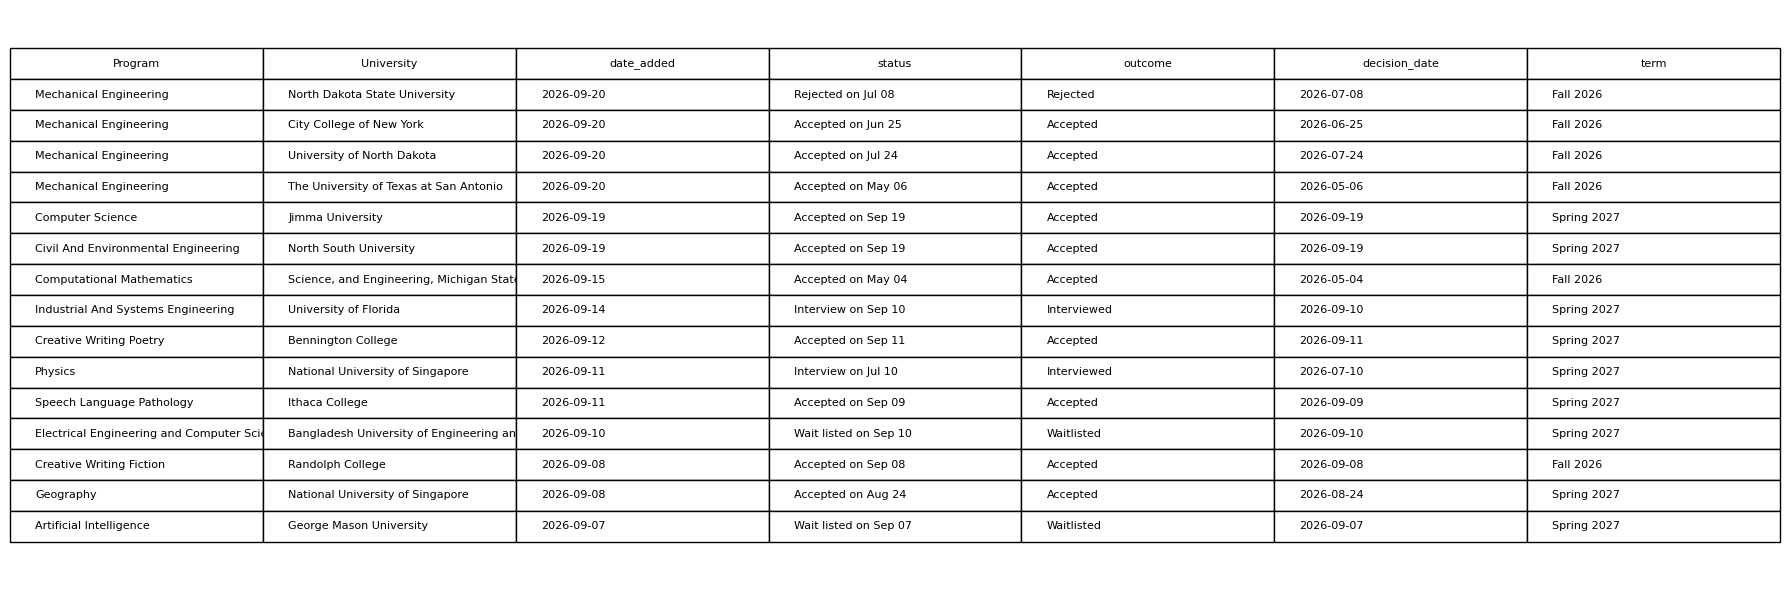

Saved: date_based.png


In [13]:
date_columns = [
    c for c in [
        "Program",
        "University",
        date_added_col,
        status_col,
        "outcome",
        "decision_date",
        term_col
    ]
    if c in df.columns
]

preview = df[date_columns].head(15).copy()

fig, ax = plt.subplots(figsize=(18, 6))
ax.axis("off")

table = ax.table(
    cellText=preview.fillna("").astype(str).values,
    colLabels=preview.columns.tolist(),
    loc="center",
    cellLoc="left"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.5)

plt.tight_layout()
plt.savefig(
    "date_based.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved: date_based.png")

### Degree and US/International validation
Keep only Master's, PhD and PsyD degrees and the International / American / Other categories.

In [14]:
degree_col = next(
    c for c in df.columns if c.lower() == "degree"
)

rows_before_degree_filter = len(df)

degree_text = (
    df[degree_col]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace("’", "'", regex=False)
)

degree_map = {
    "master's": "Master's",
    "masters": "Master's",
    "master’s": "Master's",
    "phd": "PhD",
    "psyd": "PsyD"
}

df[degree_col] = degree_text.map(degree_map)

df = df[
    df[degree_col].isin(["Master's", "PhD", "PsyD"])
].copy()

rows_after_degree_filter = len(df)

print("Remaining degree values:")
print(df[degree_col].value_counts().to_string())

Remaining degree values:
degree
PhD         21196
Master's     7641
PsyD          299


In [15]:
rows_before_us_filter = len(df)

# Standardize US/International values
us_col = "us_or_international"

us_text = (
    df[us_col]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Map values to the required categories
us_map = {
    "international": "International",
    "american": "American",
    "other": "Other",
    "us": "American",
    "u.s.": "American",
    "usa": "American",
    "u.s.a.": "American"
}

df[us_col] = us_text.map(us_map)

# Keep only the three valid categories
df = df[
    df[us_col].isin(["International", "American", "Other"])
].copy()

rows_after_us_filter = len(df)

# Verify
print("Valid US/International values:")
print(df[us_col].value_counts().to_string())

print("\nUnique values:")
print(df[us_col].unique())

Valid US/International values:
us_or_international
American         14931
International    13603
Other              126

Unique values:
['American' 'Other' 'International']


### Cleaning report and numeric conversion
Rows removed by each rule, raw vs cleaned counts, and float conversion of GPA/GRE columns.

In [16]:
# Rows removed by each cleaning rule, raw vs cleaned
cleaning_report = pd.DataFrame([
    {"Rule": "Raw rows", "Rows removed": 0, "Rows remaining": rows_raw},
    {"Rule": "program is None/missing", "Rows removed": rows_raw - rows_after_program_filter,
     "Rows remaining": rows_after_program_filter},
    {"Rule": "Degree not in Master's / PhD / PsyD", "Rows removed": rows_before_degree_filter - rows_after_degree_filter,
     "Rows remaining": rows_after_degree_filter},
    {"Rule": "US/International not International / American / Other", "Rows removed": rows_before_us_filter - rows_after_us_filter,
     "Rows remaining": rows_after_us_filter},
])
print(cleaning_report.to_string(index=False))

print("\nRaw shape:    ", raw_df.shape)
print("Cleaned shape:", df.shape)
print("Total rows removed:", len(raw_df) - len(df))
print(f"Raw rows: {len(raw_df)} | Cleaned rows: {len(df)}")

                                                 Rule  Rows removed  Rows remaining
                                             Raw rows             0           30000
                              program is None/missing             0           30000
                  Degree not in Master's / PhD / PsyD           864           29136
US/International not International / American / Other           476           28660

Raw shape:     (30000, 14)
Cleaned shape: (28660, 18)
Total rows removed: 1340
Raw rows: 30000 | Cleaned rows: 28660


In [17]:
# Convert the numeric score columns to float
numeric_score_cols = [c for c in ["gpa", "gre", "gre_v", "gre_aw"] if c in df.columns]
for c in numeric_score_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype(float)

print(df[numeric_score_cols].dtypes.to_string())

gpa       float64
gre       float64
gre_v     float64
gre_aw    float64


## 5. Derived features

## Feature Engineering

This step creates six derived features from the cleaned applicant dataset to support data quality assessment and analysis of application and decision timelines.

### 1. `has_valid_gpa`

Indicates whether an applicant has a valid GPA.

- `1`: GPA is present and between 0.0 and 4.0, inclusive.
- `0`: GPA is missing or outside the valid range.

### 2. `has_valid_gre`

Indicates whether an applicant has a valid GRE score.

- `1`: GRE score is present and greater than zero.
- `0`: GRE score is missing, zero, or negative.

### 3. `has_valid_gre_v`

Indicates whether an applicant has a valid GRE Verbal score.

- `1`: GRE Verbal score is present and greater than zero.
- `0`: GRE Verbal score is missing, zero, or negative.

### 4. `days_to_decision`

Measures the number of days between the application date (`date_added`) and the decision date (`decision_date`).

The value is calculated as:

`decision_date - date_added`

Missing decision dates stay missing (`NaN`). Negative values are kept because GradCafe entries are usually posted after the decision; `decision_speed` treats them as `Unknown`.

### 5. `decision_speed`

Categorizes the time taken to reach a decision.

| Days to Decision | Category |
|---|---|
| 0–30 days | `0-30 days` |
| 31–60 days | `31-60 days` |
| 61 days or more | `61+ days` |
| Missing or invalid duration | `Unknown` |

### 6. `application_season`

Derives the application month from the original `date_added` text and assigns each record to an application-season category.

The extraction supports abbreviated and full month names, as well as dates with prefixes such as `Added on Sep 20, 2026`. It also attempts to parse complete dates when a month name cannot be extracted.

| Application Months | `application_season` |
|---|---|
| June–July | `Early Cycle` |
| August–September | `Mid Cycle` |
| October–December | `Late Cycle` |
| January–May | `Unknown` |
| Missing or unrecognized date | `Unknown` |

For example, `Added on Sep 20, 2026` is interpreted as September (month 9) and classified as `Mid Cycle`.

### Implementation Notes

- The original date text is preserved in `raw_df` so that month information remains available even after the working DataFrame's date columns are converted to datetime values.
- Original date values are aligned with the current `df` rows using their indexes.
- The code uses Pandas and NumPy to create the derived features.
- Summary counts and sample rows are printed to validate the generated features.

These features provide indicators for applicant data quality, decision turnaround time, and application-season patterns.


In [18]:

import pandas as pd
import numpy as np
import re

# --------------------------------------------------
# 0. Identify columns regardless of capitalization,
#    spaces, or underscores
# --------------------------------------------------

def normalize_name(name):
    return re.sub(r"[\s_]+", "", str(name)).lower()


column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

gpa_col = column_lookup.get("gpa")
gre_col = column_lookup.get("gre")
gre_v_col = column_lookup.get("grev")
date_added_col = column_lookup.get("dateadded")
decision_date_col = column_lookup.get("decisiondate")

required_columns = {
    "GPA": gpa_col,
    "GRE": gre_col,
    "GRE Verbal": gre_v_col,
    "date_added": date_added_col,
    "decision_date": decision_date_col
}

missing_columns = [
    name for name, col in required_columns.items()
    if col is None
]

if missing_columns:
    raise KeyError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )


# --------------------------------------------------
# Preserve original date_added text
# before converting dates to datetime
# --------------------------------------------------

if not df.index.is_unique or not raw_df.index.is_unique:
    raise ValueError(
        "df and raw_df must have unique indexes for safe date alignment."
    )

original_date_text = (
    raw_df[date_added_col]
    .reindex(df.index)
    .astype("string")
    .str.strip()
)


# --------------------------------------------------
# 1. has_valid_gpa
# Valid GPA: between 0 and 4.0
# --------------------------------------------------

gpa = pd.to_numeric(df[gpa_col], errors="coerce")

df["has_valid_gpa"] = (
    gpa.notna() & gpa.between(0, 4.0)
).astype(int)


# --------------------------------------------------
# 2. has_valid_gre
# Valid GRE: greater than zero
# --------------------------------------------------

gre = pd.to_numeric(df[gre_col], errors="coerce")

df["has_valid_gre"] = (
    gre.notna() & gre.gt(0)
).astype(int)


# --------------------------------------------------
# 3. has_valid_gre_v
# Valid GRE Verbal: greater than zero
# --------------------------------------------------

gre_v = pd.to_numeric(df[gre_v_col], errors="coerce")

df["has_valid_gre_v"] = (
    gre_v.notna() & gre_v.gt(0)
).astype(int)


# --------------------------------------------------
# Prepare date columns
# --------------------------------------------------

df[date_added_col] = pd.to_datetime(
    df[date_added_col],
    format="mixed",
    errors="coerce"
)

df[decision_date_col] = pd.to_datetime(
    df[decision_date_col],
    format="mixed",
    errors="coerce"
)


# --------------------------------------------------
# 4. days_to_decision
# --------------------------------------------------

df["days_to_decision"] = (
    df[decision_date_col] - df[date_added_col]
).dt.days

# Missing decision dates stay NaN. Negative values are kept: GradCafe posts
# an entry after the decision, so decision_date - date_added is often negative.


# --------------------------------------------------
# 5. decision_speed
# --------------------------------------------------

days = df["days_to_decision"]

df["decision_speed"] = np.select(
    [
        days.between(0, 30),
        days.between(31, 60),
        days.ge(61)
    ],
    [
        "0-30 days",
        "31-60 days",
        "61+ days"
    ],
    default="Unknown"
)


# --------------------------------------------------
# 6. application_season
# Extract month from original date_added text.
#
# Supported examples:
# "Sep"
# "Sep 20, 2026"
# "Added on Sep 20, 2026"
# "Added on September 20, 2026"
# "2026-09-20"
# --------------------------------------------------

month_map = {
    "jan": 1,
    "feb": 2,
    "mar": 3,
    "apr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "aug": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dec": 12
}

# Extract a month name or abbreviation anywhere in the text.
# This handles the "Added on Sep 20, 2026" prefix.
month_abbreviation = (
    original_date_text
    .str.extract(
        r"\b("
        r"January|February|March|April|May|June|July|August|"
        r"September|October|November|December|"
        r"Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec"
        r")\b",
        flags=re.IGNORECASE,
        expand=False
    )
    .str.lower()
    .str[:3]
)

month_from_text = month_abbreviation.map(month_map)

# Remove "Added on" before attempting to parse a complete date.
cleaned_date_text = original_date_text.str.replace(
    r"^\s*Added\s+on\s+",
    "",
    regex=True,
    case=False
)

parsed_original_dates = pd.to_datetime(
    cleaned_date_text,
    format="mixed",
    errors="coerce"
)

month_from_date = parsed_original_dates.dt.month

# Prefer the month extracted from text.
# Use parsed dates as a fallback.
month = month_from_text.fillna(month_from_date)

# Align to the cleaned dataframe's index.
month = month.reindex(df.index)

# Apply the requested season ranges:
# June-July       -> Early Cycle
# August-September -> Mid Cycle
# October-December -> Late Cycle
# January-May      -> Unknown
# Missing dates    -> Unknown

df["application_season"] = np.select(
    [
        month.isin([6, 7]),
        month.isin([8, 9]),
        month.isin([10, 11, 12])
    ],
    [
        "Early Cycle",
        "Mid Cycle",
        "Late Cycle"
    ],
    default="Unknown"
)


# --------------------------------------------------
# 7. Display and validate results
# --------------------------------------------------

derived_columns = [
    "has_valid_gpa",
    "has_valid_gre",
    "has_valid_gre_v",
    "days_to_decision",
    "decision_speed",
    "application_season"
]

print("All derived features created successfully.")

print("\nDerived features — first 15 rows:")
print(
    df[derived_columns]
    .head(15)
    .to_string(index=False)
)

print("\nApplication season examples:")
print(
    pd.DataFrame({
        "original_date_added": original_date_text,
        "month_number": month,
        "application_season": df["application_season"]
    }).head(20).to_string(index=False)
)

print("\nApplication season counts:")
print(
    df["application_season"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nDecision speed counts:")
print(
    df["decision_speed"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nValidity indicator counts:")

for col in [
    "has_valid_gpa",
    "has_valid_gre",
    "has_valid_gre_v"
]:
    print(f"\n{col}:")
    print(
        df[col]
        .value_counts(dropna=False)
        .to_string()
    )


All derived features created successfully.

Derived features — first 15 rows:
 has_valid_gpa  has_valid_gre  has_valid_gre_v  days_to_decision decision_speed application_season
             1              0                0             -74.0        Unknown          Mid Cycle
             1              0                0             -87.0        Unknown          Mid Cycle
             1              0                0             -58.0        Unknown          Mid Cycle
             1              0                0            -137.0        Unknown          Mid Cycle
             0              0                0               0.0      0-30 days          Mid Cycle
             1              0                0               0.0      0-30 days          Mid Cycle
             1              0                0            -134.0        Unknown          Mid Cycle
             0              0                0              -4.0        Unknown          Mid Cycle
             1              0  

In [19]:
# Check indicator values
for col in [
    "has_valid_gpa",
    "has_valid_gre",
    "has_valid_gre_v"
]:
    print(f"\n{col} values:")
    print(df[col].value_counts(dropna=False).to_string())

# Check decision categories
print("\nDecision speed:")
print(df["decision_speed"].value_counts(dropna=False).to_string())

# Check application seasons
print("\nApplication season:")
print(df["application_season"].value_counts(dropna=False).to_string())

# Check missing decision intervals
print(
    "\nMissing days_to_decision:",
    df["days_to_decision"].isna().sum()
)

# Display all derived features
derived_columns = [
    "has_valid_gpa",
    "has_valid_gre",
    "has_valid_gre_v",
    "days_to_decision",
    "decision_speed",
    "application_season"
]

print("\nDerived feature preview:")
print(df[derived_columns].head(15).to_string(index=False))


has_valid_gpa values:
has_valid_gpa
1    17303
0    11357

has_valid_gre values:
has_valid_gre
0    26297
1     2363

has_valid_gre_v values:
has_valid_gre_v
0    26665
1     1995

Decision speed:
decision_speed
0-30 days     16447
Unknown       11651
61+ days        406
31-60 days      156

Application season:
application_season
Unknown        28477
Early Cycle      127
Mid Cycle         56

Missing days_to_decision: 11

Derived feature preview:
 has_valid_gpa  has_valid_gre  has_valid_gre_v  days_to_decision decision_speed application_season
             1              0                0             -74.0        Unknown          Mid Cycle
             1              0                0             -87.0        Unknown          Mid Cycle
             1              0                0             -58.0        Unknown          Mid Cycle
             1              0                0            -137.0        Unknown          Mid Cycle
             0              0                0       

### Float columns preview

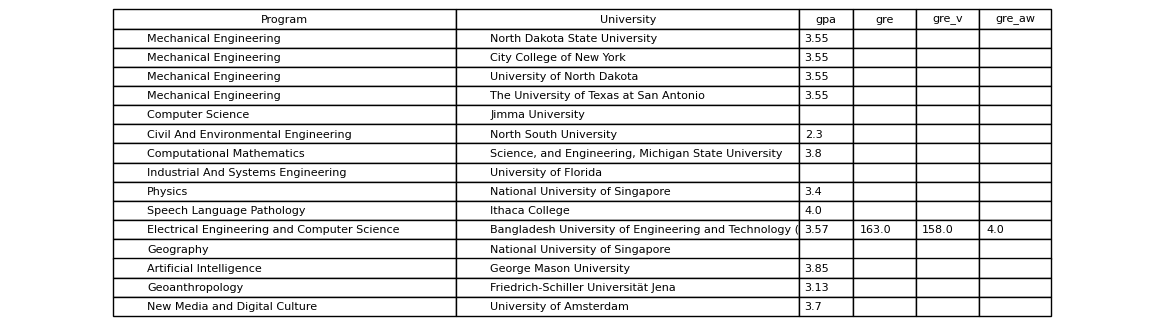

Saved compact image: float_columns.png


In [20]:
# Select columns for the screenshot
numeric_columns = [
    col for col in df.columns
    if normalize_name(col) in ["gpa", "gre", "grev", "greaw"]
]

preview_columns = [
    col for col in ["Program", "University", "Degree"]
    if col in df.columns
] + numeric_columns

preview = df[preview_columns].head(15).fillna("").astype(str)

headers = preview.columns.tolist()
cell_data = preview.values.tolist()

# Calculate compact column widths based on text length
max_lengths = [
    max(len(str(headers[i])), *(len(str(row[i])) for row in cell_data))
    for i in range(len(headers))
]

# Use a smaller width per character, with tighter limits
column_widths = [
    min(max(length * 0.008 + 0.015, 0.045), 0.30)
    for length in max_lengths
]

# Create a compact table
fig_width = max(7, sum(column_widths) * 18)
fig, ax = plt.subplots(figsize=(fig_width, 3.8))
ax.axis("off")

table = ax.table(
    cellText=cell_data,
    colLabels=headers,
    colWidths=column_widths,
    loc="center",
    cellLoc="left"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.15)

plt.savefig(
    "float_columns.png",
    dpi=150,
    bbox_inches="tight",
    pad_inches=0.05
)
plt.show()
plt.close()

print("Saved compact image: float_columns.png")

## 6. Summary statistics
Descriptive statistics for GPA, GRE, GRE V and GRE AW saved to `summary_statistics.csv`.

In [21]:

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Identify numeric columns
#    Supports variations such as GRE V, gre_v, GRE AW, gre_aw
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

target_columns = {
    "GPA": ["gpa"],
    "GRE": ["gre"],
    "GRE V": ["gre v", "gre_v", "gre verbal", "grev"],
    "GRE AW": [
        "gre aw", "gre_aw", "gre analytical writing",
        "gre writing", "greaw"
    ]
}

available_columns = {}

for label, alternatives in target_columns.items():
    for alternative in alternatives:
        key = normalize_name(alternative)

        if key in column_lookup:
            available_columns[label] = column_lookup[key]
            break

if not available_columns:
    raise KeyError(
        "None of the required columns were found. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Columns included in the summary:")
print(available_columns)


# --------------------------------------------------
# 2. Compute descriptive statistics
# --------------------------------------------------

statistics = {}

for label, column in available_columns.items():

    # Convert values to numeric; invalid values become NaN
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    statistics[label] = {
        "count": values.count(),
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(ddof=1),
        "min": values.min(),
        "max": values.max(),
        "25%": values.quantile(0.25),
        "50%": values.quantile(0.50),
        "75%": values.quantile(0.75)
    }


# Rows = statistics; columns = numeric variables
summary_statistics = pd.DataFrame(statistics)

# Consistent row ordering
summary_statistics = summary_statistics.reindex([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max",
    "25%",
    "50%",
    "75%"
])

# Round numeric results for readability
summary_statistics.loc[
    ["mean", "median", "std", "min", "max", "25%", "50%", "75%"]
] = summary_statistics.loc[
    ["mean", "median", "std", "min", "max", "25%", "50%", "75%"]
].round(3)


# --------------------------------------------------
# 3. Display and save the summary table
# --------------------------------------------------

print("\nDescriptive Statistics:")
print(summary_statistics.to_string())

output_file = "summary_statistics.csv"

summary_statistics.to_csv(output_file, index=True)

print(f"\nSummary statistics saved to: {output_file}")


Columns included in the summary:
{'GPA': 'gpa', 'GRE': 'gre', 'GRE V': 'gre_v', 'GRE AW': 'gre_aw'}

Descriptive Statistics:
              GPA       GRE     GRE V    GRE AW
count   17421.000  2363.000  1995.000  1799.000
mean        3.797   263.193   161.625     4.353
median      3.850   316.000   161.000     4.500
std         0.569    87.912    27.447     0.793
min         0.100   130.000   134.000     0.600
max        29.650   999.000   999.000     6.700
25%         3.680   168.000   157.000     4.000
50%         3.850   316.000   161.000     4.500
75%         3.960   328.000   166.000     5.000

Summary statistics saved to: summary_statistics.csv


## 7. Outlier analysis
Z-score outliers (|z| > 3) for GPA and GRE using `scipy.stats.zscore`; outliers are flagged and kept.

GPA potential outliers: 63
GRE potential outliers: 8

GPA outlier records:
         gpa
72      2.00
600    15.40
632     0.10
2621    8.69
3069    9.10
3434    8.25
3707    9.10
3834    9.99
4114    9.30
4115    9.90
4362    9.30
5151    9.99
5582    9.99
6156    9.99
6305   29.65
6346    9.99
6439    9.99
6467   29.64
6864   29.40
6865   29.40
8501    1.70
11089   8.86
11094   8.88
11105   9.99
11107   9.99
11529   6.90
13695   6.70
14055  27.30
14439   8.21
15250   9.99
16091   9.51
16199   6.00
16982   6.74
17822   1.00
18101   9.45
18191   9.89
19139   1.50
19536   0.67
19934   1.55
19957   0.67
19973   0.69
21278   9.99
21793   1.30
21828   1.30
22395   1.30
22548   8.58
23556   7.00
24303   1.29
24857   9.99
25091   9.99
25234   9.99
25420   6.70
26222   9.99
26719   9.99
26721   2.00
27907   9.99
28133   9.99
28416   9.99
28430   9.99
28694   9.99
28878   1.40
28988   8.02
29258   1.30

GRE outlier records:
         gre
14177  655.0
16057  999.0
16806  870.0
18144  990.0
23556 

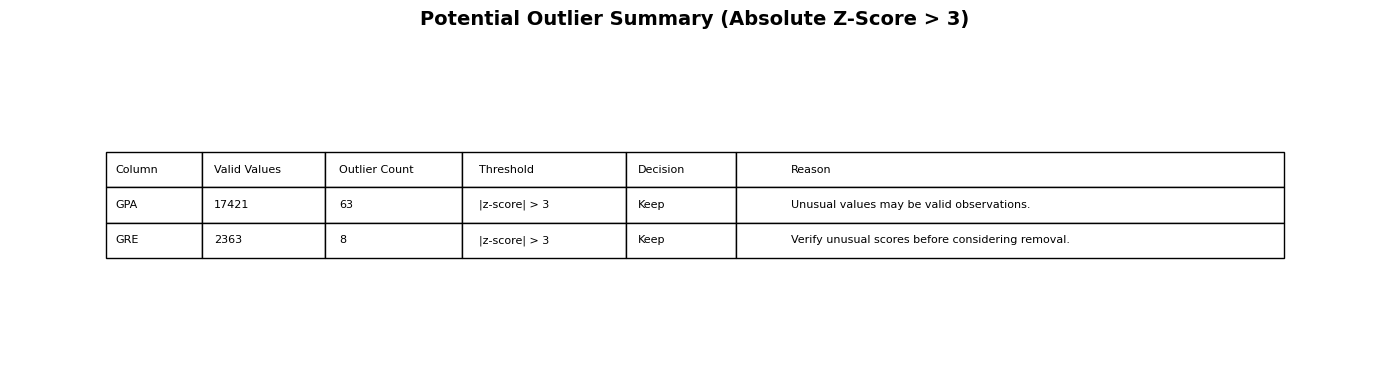

Saved outlier_summary.png

Outlier flag counts:
gpa_outlier    63
gre_outlier     8

Outlier flag data types:
gpa_outlier    bool
gre_outlier    bool


In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

# --------------------------------------------------
# 1. Identify GPA and GRE columns
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

gpa_col = column_lookup.get("gpa")
gre_col = column_lookup.get("gre")

if gpa_col is None or gre_col is None:
    raise KeyError(
        "GPA or GRE column not found. "
        f"Available columns: {df.columns.tolist()}"
    )


# --------------------------------------------------
# 2. Calculate z-scores and flag potential outliers
# --------------------------------------------------

# Convert columns to numeric
gpa = pd.to_numeric(df[gpa_col], errors="coerce")
gre = pd.to_numeric(df[gre_col], errors="coerce")

# Calculate z-scores, ignoring missing values
gpa_zscore = pd.Series(
    zscore(gpa, nan_policy="omit"),
    index=df.index
)

gre_zscore = pd.Series(
    zscore(gre, nan_policy="omit"),
    index=df.index
)

# Flag values with absolute z-score greater than 3.
# Missing or undefined z-scores are not flagged.
df["gpa_outlier"] = (
    gpa_zscore.abs().gt(3).fillna(False)
).astype(bool)

df["gre_outlier"] = (
    gre_zscore.abs().gt(3).fillna(False)
).astype(bool)


# --------------------------------------------------
# 3. Count potential outliers
# --------------------------------------------------

gpa_outlier_count = int(df["gpa_outlier"].sum())
gre_outlier_count = int(df["gre_outlier"].sum())

gpa_valid_count = int(gpa.notna().sum())
gre_valid_count = int(gre.notna().sum())

print("GPA potential outliers:", gpa_outlier_count)
print("GRE potential outliers:", gre_outlier_count)

print("\nGPA outlier records:")
print(
    df.loc[df["gpa_outlier"], [gpa_col]].to_string(index=True)
)

print("\nGRE outlier records:")
print(
    df.loc[df["gre_outlier"], [gre_col]].to_string(index=True)
)


# --------------------------------------------------
# 4. Create the outlier summary table
# --------------------------------------------------

summary = pd.DataFrame([
    {
        "Column": "GPA",
        "Valid Values": gpa_valid_count,
        "Outlier Count": gpa_outlier_count,
        "Threshold": "|z-score| > 3",
        "Decision": "Keep",
        "Reason": "Unusual values may be valid observations."
    },
    {
        "Column": "GRE",
        "Valid Values": gre_valid_count,
        "Outlier Count": gre_outlier_count,
        "Threshold": "|z-score| > 3",
        "Decision": "Keep",
        "Reason": "Verify unusual scores before considering removal."
    }
])

print("\nOutlier Summary:")
print(summary.to_string(index=False))


# --------------------------------------------------
# 5. Save summary as CSV
# --------------------------------------------------

summary.to_csv("outlier_summary.csv", index=False)

print("\nSaved outlier_summary.csv")


# --------------------------------------------------
# 6. Save a screenshot-style summary as PNG
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.axis("off")

ax.set_title(
    "Potential Outlier Summary (Absolute Z-Score > 3)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

table = ax.table(
    cellText=summary.values,
    colLabels=summary.columns,
    cellLoc="left",
    colLoc="left",
    loc="center",
    colWidths=[0.07, 0.09, 0.10, 0.12, 0.08, 0.40]
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2.0)

plt.tight_layout()
plt.savefig(
    "outlier_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved outlier_summary.png")


# --------------------------------------------------
# 7. Confirm the Boolean columns
# --------------------------------------------------

print("\nOutlier flag counts:")
print(df[["gpa_outlier", "gre_outlier"]].sum().to_string())

print("\nOutlier flag data types:")
print(df[["gpa_outlier", "gre_outlier"]].dtypes.to_string())


## 8. Statistical analysis with SciPy
### 8a. Pearson correlations (GRE vs GRE V, GPA vs GRE)

In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --------------------------------------------------
# 1. Identify columns regardless of spaces/underscores
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

gpa_col = column_lookup.get("gpa")
gre_col = column_lookup.get("gre")
gre_v_col = column_lookup.get("grev")

required = {
    "GPA": gpa_col,
    "GRE": gre_col,
    "GRE V": gre_v_col
}

missing = [name for name, col in required.items() if col is None]

if missing:
    raise KeyError(
        f"Missing required columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )


# --------------------------------------------------
# 2. Helper function to calculate Pearson correlation
# --------------------------------------------------

def calculate_correlation(dataframe, col_x, col_y):
    # Convert both variables to numeric
    x = pd.to_numeric(dataframe[col_x], errors="coerce")
    y = pd.to_numeric(dataframe[col_y], errors="coerce")

    # Keep only rows where both values are finite and non-zero
    valid = (
        x.notna()
        & y.notna()
        & np.isfinite(x)
        & np.isfinite(y)
        & x.ne(0)
        & y.ne(0)
    )

    x_valid = x.loc[valid].astype(float)
    y_valid = y.loc[valid].astype(float)

    n = len(x_valid)

    if n < 3:
        raise ValueError(
            f"Not enough valid non-zero pairs for {col_x} and {col_y}: n={n}"
        )

    if x_valid.nunique() < 2 or y_valid.nunique() < 2:
        raise ValueError(
            f"Cannot calculate Pearson correlation for {col_x} and {col_y}: "
            "at least one variable has no variation."
        )

    result = pearsonr(x_valid, y_valid)

    return {
        "Variable 1": col_x,
        "Variable 2": col_y,
        "Valid Pairs (n)": n,
        "Correlation Coefficient (r)": result.statistic,
        "P-value": result.pvalue
    }


# --------------------------------------------------
# 3. Perform the two required correlation analyses
# --------------------------------------------------

gre_grev_result = calculate_correlation(
    df, gre_col, gre_v_col
)

gpa_gre_result = calculate_correlation(
    df, gpa_col, gre_col
)

results = [gre_grev_result, gpa_gre_result]


# --------------------------------------------------
# 4. Generate interpretations
# --------------------------------------------------

def interpret_correlation(result):
    r = result["Correlation Coefficient (r)"]
    p = result["P-value"]
    n = result["Valid Pairs (n)"]

    abs_r = abs(r)

    if abs_r < 0.10:
        strength = "negligible"
    elif abs_r < 0.30:
        strength = "weak"
    elif abs_r < 0.50:
        strength = "moderate"
    else:
        strength = "strong"

    if r > 0:
        direction = "positive"
    elif r < 0:
        direction = "negative"
    else:
        direction = "no"

    if p < 0.05:
        significance = (
            f"The correlation is statistically significant "
            f"(p = {p:.4g}), providing evidence of a linear association "
            "between the two variables."
        )
    else:
        significance = (
            f"The correlation is not statistically significant "
            f"(p = {p:.4g}); the analysis does not provide sufficient "
            "evidence of a linear association."
        )

    if direction == "no":
        relationship = "There is no observed linear correlation."
    else:
        relationship = (
            f"The variables have a {strength} {direction} "
            f"linear correlation (r = {r:.3f}) across {n} valid pairs."
        )

    return relationship + " " + significance


# --------------------------------------------------
# 5. Print results
# --------------------------------------------------

for result in results:
    print("\n" + "=" * 60)
    print(f"{result['Variable 1']} vs. {result['Variable 2']}")
    print(f"Valid pairs: {result['Valid Pairs (n)']}")
    print(
        f"Pearson correlation coefficient: "
        f"{result['Correlation Coefficient (r)']:.4f}"
    )
    print(f"P-value: {result['P-value']:.6g}")
    print("Interpretation:")
    print(interpret_correlation(result))



gre vs. gre_v
Valid pairs: 1894
Pearson correlation coefficient: 0.2814
P-value: 8.15085e-36
Interpretation:
The variables have a weak positive linear correlation (r = 0.281) across 1894 valid pairs. The correlation is statistically significant (p = 8.151e-36), providing evidence of a linear association between the two variables.

gpa vs. gre
Valid pairs: 2116
Pearson correlation coefficient: 0.0441
P-value: 0.0425985
Interpretation:
The variables have a negligible positive linear correlation (r = 0.044) across 2116 valid pairs. The correlation is statistically significant (p = 0.0426), providing evidence of a linear association between the two variables.


### 8b. GPA comparison: Accepted vs Rejected (Welch's t-test)

In [24]:

import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# --------------------------------------------------
# 1. Identify GPA and outcome columns
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

gpa_col = column_lookup.get("gpa")
outcome_col = column_lookup.get("outcome")

if gpa_col is None or outcome_col is None:
    raise KeyError(
        "GPA or outcome column not found. "
        f"Available columns: {df.columns.tolist()}"
    )


# --------------------------------------------------
# 2. Prepare valid GPA values for each group
# --------------------------------------------------

gpa = pd.to_numeric(df[gpa_col], errors="coerce")
outcome = df[outcome_col].astype("string").str.strip().str.lower()

# Keep finite GPA values within the valid 0-4.0 range
valid_gpa = gpa.notna() & np.isfinite(gpa) & gpa.between(0, 4.0)

accepted_gpa = gpa.loc[
    valid_gpa & outcome.eq("accepted")
].dropna()

rejected_gpa = gpa.loc[
    valid_gpa & outcome.eq("rejected")
].dropna()

print("Accepted applicants with valid GPA:", len(accepted_gpa))
print("Rejected applicants with valid GPA:", len(rejected_gpa))


# --------------------------------------------------
# 3. Compare group sizes and GPA averages
# --------------------------------------------------

if len(accepted_gpa) < 2 or len(rejected_gpa) < 2:
    raise ValueError(
        "At least two valid GPA values are required in each group."
    )

accepted_mean = accepted_gpa.mean()
rejected_mean = rejected_gpa.mean()

accepted_median = accepted_gpa.median()
rejected_median = rejected_gpa.median()

print("\nGPA descriptive statistics:")
print(f"Accepted mean GPA: {accepted_mean:.3f}")
print(f"Rejected mean GPA: {rejected_mean:.3f}")
print(f"Accepted median GPA: {accepted_median:.3f}")
print(f"Rejected median GPA: {rejected_median:.3f}")


# --------------------------------------------------
# 4. Welch's two-sample t-test
# --------------------------------------------------

# Welch's t-test does not assume equal population variances.
test_result = ttest_ind(
    accepted_gpa,
    rejected_gpa,
    equal_var=False,
    alternative="two-sided"
)

ttest_statistic = test_result.statistic
ttest_p_value = test_result.pvalue
mean_difference = accepted_mean - rejected_mean

print("\nGroup Comparison: Accepted vs. Rejected")
print("Test used: Welch's independent two-sample t-test")
print(f"Test statistic: {ttest_statistic:.4f}")
print(f"P-value: {ttest_p_value:.6g}")
print(f"Mean GPA difference (Accepted - Rejected): {mean_difference:.3f}")


# --------------------------------------------------
# 5. Generate interpretation
# --------------------------------------------------

if ttest_p_value < 0.05:
    if mean_difference > 0:
        direction = "Accepted applicants had a higher average GPA."
    elif mean_difference < 0:
        direction = "Rejected applicants had a higher average GPA."
    else:
        direction = (
            "The observed group means are equal, despite the test result."
        )

    interpretation = (
        f"{direction} The difference in mean GPA is statistically "
        f"significant at the 0.05 level (p = {ttest_p_value:.4g})."
    )
else:
    interpretation = (
        f"The mean GPA difference was not statistically significant "
        f"(p = {ttest_p_value:.4g}). This analysis does not provide sufficient "
        "evidence that the population mean GPAs differ; it does not prove "
        "that the groups are identical."
    )

print("\nInterpretation:")
print(interpretation)


# --------------------------------------------------
# 6. Save group comparison results
# --------------------------------------------------

group_summary = pd.DataFrame([
    {
        "Group": "Accepted",
        "Valid GPA Count": len(accepted_gpa),
        "Mean GPA": accepted_mean,
        "Median GPA": accepted_median,
        "Standard Deviation": accepted_gpa.std()
    },
    {
        "Group": "Rejected",
        "Valid GPA Count": len(rejected_gpa),
        "Mean GPA": rejected_mean,
        "Median GPA": rejected_median,
        "Standard Deviation": rejected_gpa.std()
    }
])

test_summary = pd.DataFrame([{
    "Test": "Welch's independent two-sample t-test",
    "Test Statistic": ttest_statistic,
    "P-value": ttest_p_value,
    "Mean Difference (Accepted - Rejected)": mean_difference,
    "Interpretation": interpretation
}])

group_summary.to_csv("gpa_group_summary.csv", index=False)
test_summary.to_csv("gpa_test_results.csv", index=False)

print("\nSaved gpa_group_summary.csv")
print("Saved gpa_test_results.csv")


Accepted applicants with valid GPA: 7010
Rejected applicants with valid GPA: 7978

GPA descriptive statistics:
Accepted mean GPA: 3.762
Rejected mean GPA: 3.781
Accepted median GPA: 3.840
Rejected median GPA: 3.850

Group Comparison: Accepted vs. Rejected
Test used: Welch's independent two-sample t-test
Test statistic: -4.7699
P-value: 1.86157e-06
Mean GPA difference (Accepted - Rejected): -0.019

Interpretation:
Rejected applicants had a higher average GPA. The difference in mean GPA is statistically significant at the 0.05 level (p = 1.862e-06).

Saved gpa_group_summary.csv
Saved gpa_test_results.csv


### 8c. Chi-square test: Degree vs outcome

In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# --------------------------------------------------
# 1. Identify Degree and outcome columns
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

degree_col = column_lookup.get("degree")
outcome_col = column_lookup.get("outcome")

if degree_col is None or outcome_col is None:
    raise KeyError(
        "Degree or outcome column not found. "
        f"Available columns: {df.columns.tolist()}"
    )


# --------------------------------------------------
# 2. Prepare categorical data
# --------------------------------------------------

analysis_df = df[[degree_col, outcome_col]].copy()

analysis_df[degree_col] = (
    analysis_df[degree_col].astype("string").str.strip()
)

analysis_df[outcome_col] = (
    analysis_df[outcome_col].astype("string").str.strip()
)

# Exclude missing and unknown categories
analysis_df = analysis_df.dropna(
    subset=[degree_col, outcome_col]
)

analysis_df = analysis_df[
    (analysis_df[degree_col] != "")
    & (analysis_df[outcome_col] != "")
    & (analysis_df[degree_col].str.lower() != "unknown")
    & (analysis_df[outcome_col].str.lower() != "unknown")
].copy()


# --------------------------------------------------
# 3. Create contingency table
# --------------------------------------------------

contingency_table = pd.crosstab(
    analysis_df[degree_col],
    analysis_df[outcome_col]
)

if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
    raise ValueError(
        "The chi-square test requires at least two Degree categories "
        "and two outcome categories."
    )

print("Contingency Table: Degree vs. Outcome")
print(contingency_table.to_string())



# --------------------------------------------------
# 4. Run chi-square test of independence
# --------------------------------------------------

chi2_stat, chi2_p_value, degrees_freedom, expected = chi2_contingency(
    contingency_table
)

expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nChi-square Test Results")
print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {degrees_freedom}")
print(f"P-value: {chi2_p_value:.6g}")

print("\nExpected frequencies:")
print(expected_table.round(2).to_string())


# --------------------------------------------------
# 5. Generate interpretation
# --------------------------------------------------

if chi2_p_value < 0.05:
    interpretation = (
        f"The association between Degree and outcome is statistically "
        f"significant (chi-square = {chi2_stat:.3f}, "
        f"p = {chi2_p_value:.4g}). This suggests that the distribution of "
        f"outcomes differs across degree categories. The test does not "
        f"establish causation."
    )
else:
    interpretation = (
        f"No statistically significant association was detected between "
        f"Degree and outcome (chi-square = {chi2_stat:.3f}, "
        f"p = {chi2_p_value:.4g}). The analysis does not provide sufficient "
        f"evidence that outcome distributions differ by degree category."
    )

print("\nInterpretation:")
print(interpretation)


# --------------------------------------------------
# 6. Check expected cell frequencies
# --------------------------------------------------

small_expected_count = int((expected < 5).sum())
total_cells = expected.size

print(
    f"\nExpected cells below 5: {small_expected_count} of {total_cells}"
)

if small_expected_count > 0:
    print(
        "Caution: Some expected frequencies are below 5. "
        "Interpret the chi-square approximation cautiously; "
        "consider combining defensible categories or an appropriate "
        "exact/Monte Carlo test."
    )


Contingency Table: Degree vs. Outcome
outcome   Accepted  Interviewed  Rejected  Waitlisted
degree                                               
Master's      5047          325      1613         419
PhD           5417         1485     11932        2118
PsyD           105           75        93          20

Chi-square Test Results
Chi-square statistic: 4437.6646
Degrees of freedom: 6
P-value: 0

Expected frequencies:
outcome   Accepted  Interviewed  Rejected  Waitlisted
degree                                               
Master's   2731.43       487.16   3524.58      660.83
PhD        7729.47      1378.57   9973.94     1870.02
PsyD        108.09        19.28    139.48       26.15

Interpretation:
The association between Degree and outcome is statistically significant (chi-square = 4437.665, p = 0). This suggests that the distribution of outcomes differs across degree categories. The test does not establish causation.

Expected cells below 5: 0 of 12


## 9. Visualizations
Six Matplotlib figures saved as separate PNG files.

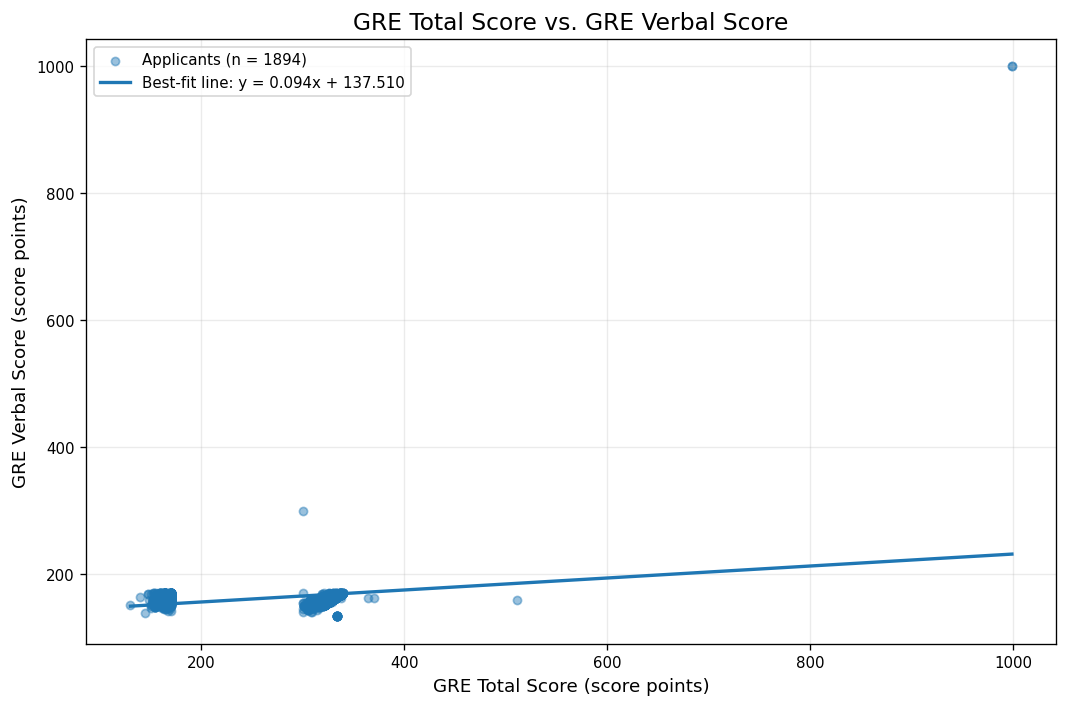

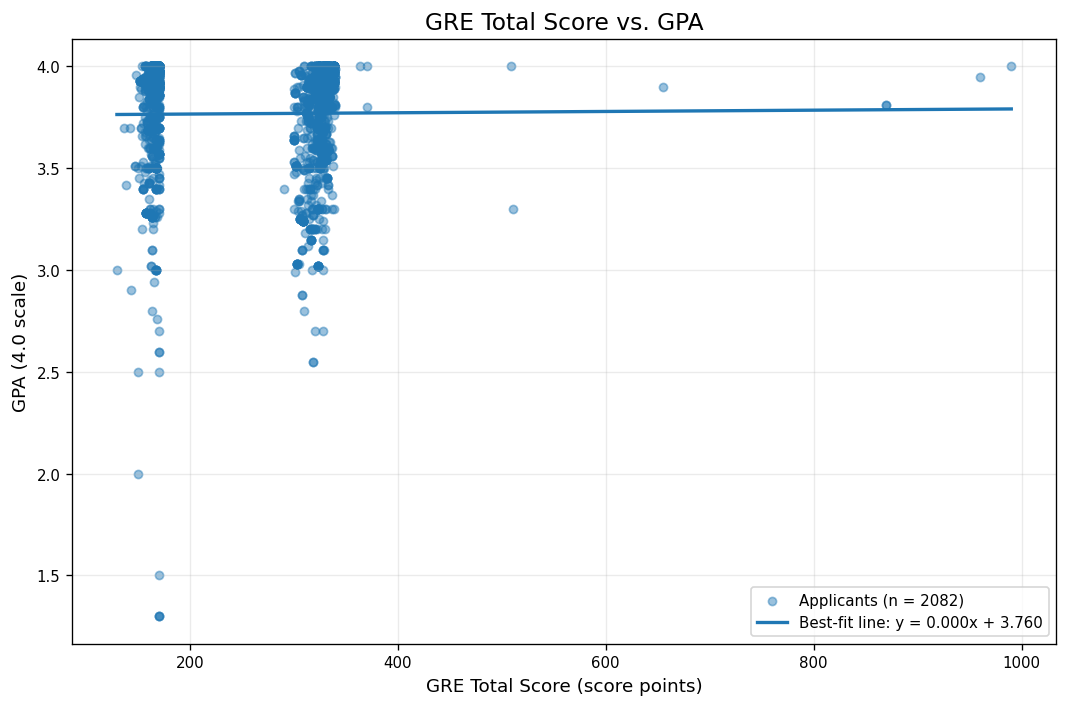

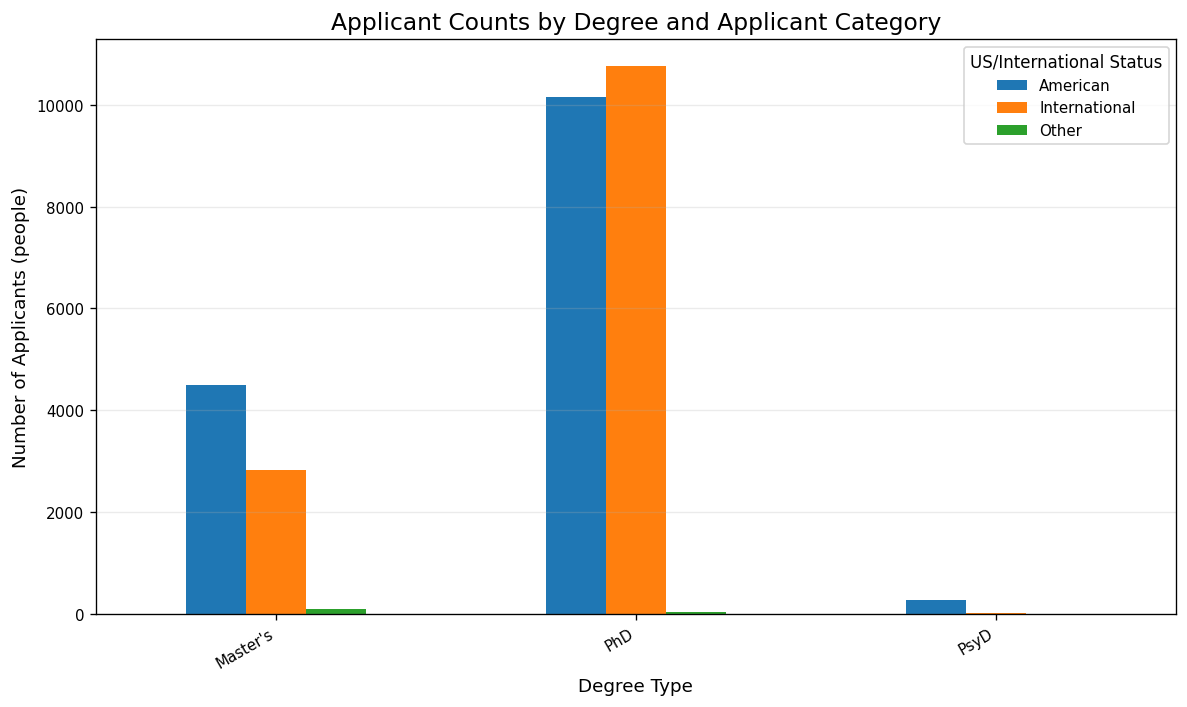

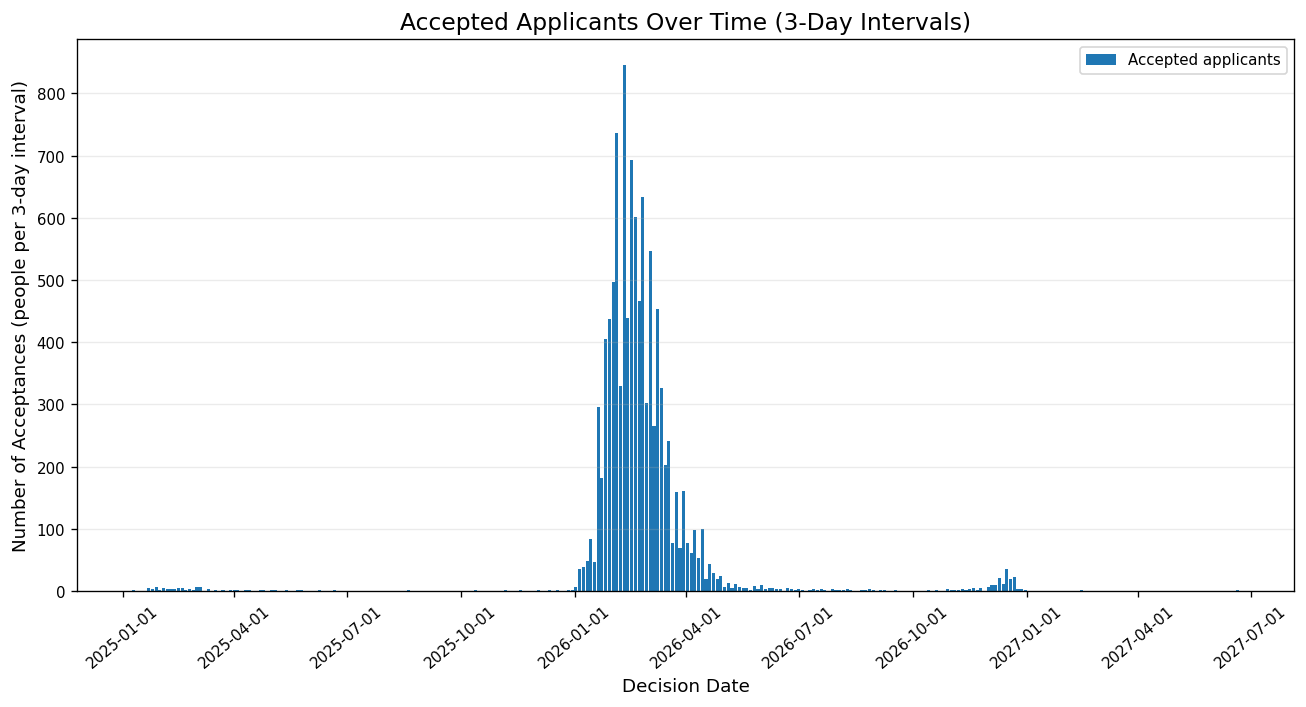

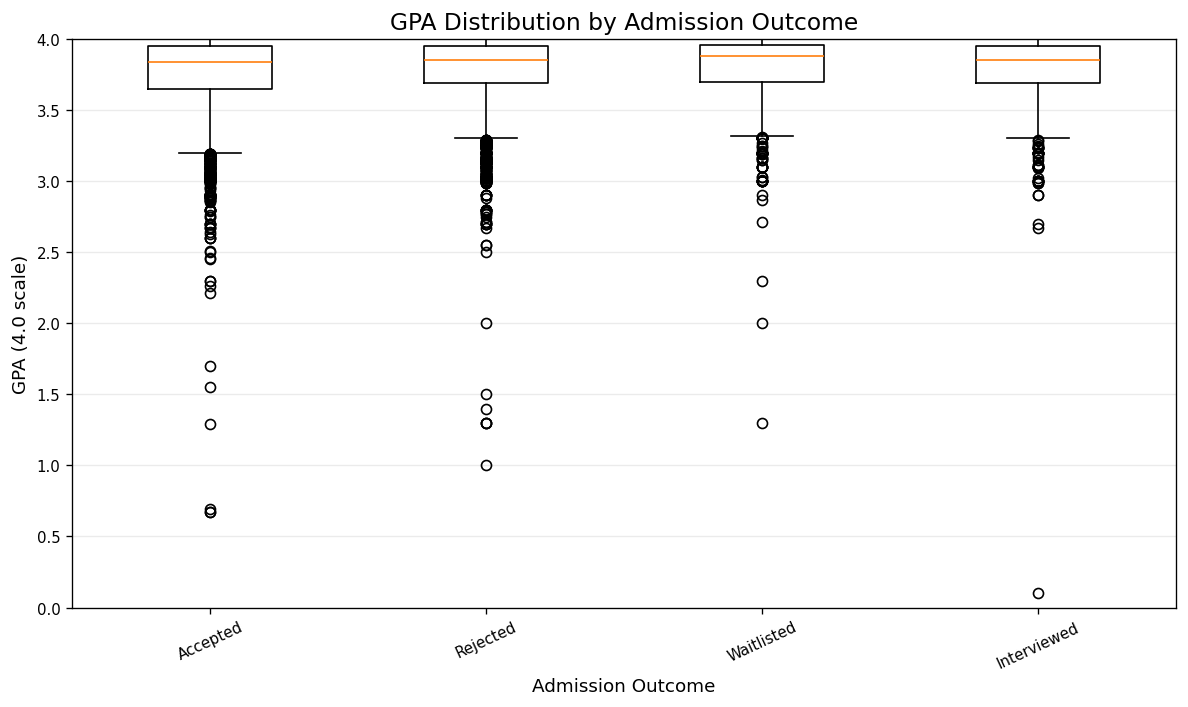

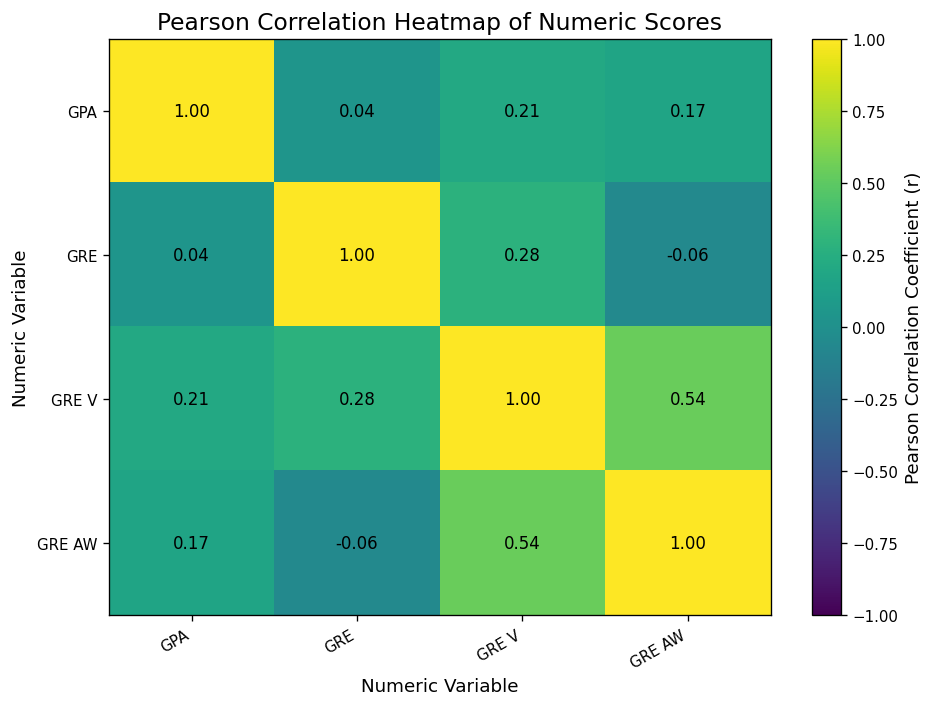


Visualization files generated:
- GRE-vs-GRE-V.png
- GPA-vs-GRE.png
- Degree-vs-International.png
- Acceptances-over-Time.png
- GPA-by-Outcome.png
- Numeric-Correlation-Heatmap.png


In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# 0. Identify columns
# --------------------------------------------------

def normalize_name(name):
    return "".join(
        char.lower()
        for char in str(name)
        if char.isalnum()
    )

column_lookup = {
    normalize_name(col): col
    for col in df.columns
}

gpa_col = column_lookup.get("gpa")
gre_col = column_lookup.get("gre")
gre_v_col = column_lookup.get("grev")
gre_aw_col = column_lookup.get("greaw")
degree_col = column_lookup.get("degree")
outcome_col = column_lookup.get("outcome")
decision_date_col = column_lookup.get("decisiondate")

us_col = next(
    (
        col for col in df.columns
        if normalize_name(col) in {
            "usorinternational",
            "usorintl",
            "usinternational",
            "usintl"
        }
    ),
    None
)

required = {
    "GPA": gpa_col,
    "GRE": gre_col,
    "GRE V": gre_v_col,
    "Degree": degree_col,
    "outcome": outcome_col,
    "decision_date": decision_date_col,
    "US/International": us_col
}

missing = [name for name, col in required.items() if col is None]

if missing:
    raise KeyError(
        f"Missing columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert numeric values
gpa = pd.to_numeric(df[gpa_col], errors="coerce")
gre = pd.to_numeric(df[gre_col], errors="coerce")
gre_v = pd.to_numeric(df[gre_v_col], errors="coerce")

outcome = df[outcome_col].astype("string").str.strip()
degree = df[degree_col].astype("string").str.strip()
us_group = df[us_col].astype("string").str.strip()

# Consistent plotting settings
plt.rcParams.update({
    "figure.figsize": (9, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 120
})


# --------------------------------------------------
# Helper: Scatter plot with NumPy best-fit line
# --------------------------------------------------

def scatter_with_best_fit(x, y, title, xlabel, ylabel, filename):
    valid = (
        x.notna() & y.notna()
        & np.isfinite(x) & np.isfinite(y)
        & x.gt(0) & y.gt(0)
    )

    x_values = x.loc[valid].to_numpy(dtype=float)
    y_values = y.loc[valid].to_numpy(dtype=float)

    if len(x_values) < 2 or np.unique(x_values).size < 2:
        raise ValueError(
            f"Not enough valid data or variation to fit a line for {title}."
        )

    # NumPy linear best-fit: y = slope*x + intercept
    slope, intercept = np.polyfit(x_values, y_values, 1)

    x_line = np.linspace(x_values.min(), x_values.max(), 200)
    y_line = slope * x_line + intercept

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(
        x_values,
        y_values,
        alpha=0.45,
        s=24,
        label=f"Applicants (n = {len(x_values)})"
    )

    ax.plot(
        x_line,
        y_line,
        linewidth=2,
        label=f"Best-fit line: y = {slope:.3f}x + {intercept:.3f}"
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# --------------------------------------------------
# 1. GRE vs GRE Verbal scatter plot
# --------------------------------------------------

scatter_with_best_fit(
    x=gre,
    y=gre_v,
    title="GRE Total Score vs. GRE Verbal Score",
    xlabel="GRE Total Score (score points)",
    ylabel="GRE Verbal Score (score points)",
    filename="GRE-vs-GRE-V.png"
)


# --------------------------------------------------
# 2. GPA vs GRE scatter plot
# --------------------------------------------------

# Filter GPA to its 4.0 scale before plotting
gpa_for_plot = gpa.where(gpa.le(4.0))

scatter_with_best_fit(
    x=gre,
    y=gpa_for_plot,
    title="GRE Total Score vs. GPA",
    xlabel="GRE Total Score (score points)",
    ylabel="GPA (4.0 scale)",
    filename="GPA-vs-GRE.png"
)


# --------------------------------------------------
# 3. Degree vs US/International bar chart
# --------------------------------------------------

category_df = pd.DataFrame({
    "Degree": degree,
    "Applicant Category": us_group
}).dropna()

category_df = category_df[
    category_df["Degree"].str.strip().ne("")
    & category_df["Applicant Category"].str.strip().ne("")
]

degree_counts = pd.crosstab(
    category_df["Degree"],
    category_df["Applicant Category"]
)

fig, ax = plt.subplots(figsize=(10, 6))
degree_counts.plot(kind="bar", ax=ax)

ax.set_title("Applicant Counts by Degree and Applicant Category")
ax.set_xlabel("Degree Type")
ax.set_ylabel("Number of Applicants (people)")
ax.legend(title="US/International Status")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    "Degree-vs-International.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# --------------------------------------------------
# 4. Accepted applicants over time, 3-day intervals
# --------------------------------------------------

decision_dates = pd.to_datetime(
    df[decision_date_col],
    errors="coerce",
    format="mixed"
)

accepted_mask = (
    outcome.str.casefold().eq("accepted")
    & decision_dates.notna()
)

accepted_dates = decision_dates.loc[accepted_mask]

fig, ax = plt.subplots(figsize=(11, 6))

if not accepted_dates.empty:
    date_counts = pd.Series(
        1,
        index=pd.DatetimeIndex(accepted_dates.to_numpy())
    ).sort_index()

    three_day_counts = date_counts.resample(
        "3D",
        origin=date_counts.index.min().normalize()
    ).sum()

    ax.bar(
        three_day_counts.index,
        three_day_counts.values,
        width=2.5,
        align="center",
        label="Accepted applicants"
    )

    ax.legend(loc="best")
else:
    ax.text(
        0.5, 0.5,
        "No accepted applicants with valid decision dates",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

ax.set_title("Accepted Applicants Over Time (3-Day Intervals)")
ax.set_xlabel("Decision Date")
ax.set_ylabel("Number of Acceptances (people per 3-day interval)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    "Acceptances-over-Time.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# --------------------------------------------------
# 5. GPA boxplot by outcome
# --------------------------------------------------

box_df = pd.DataFrame({
    "GPA": gpa,
    "Outcome": outcome
}).dropna()

box_df = box_df[
    box_df["GPA"].between(0, 4.0)
    & box_df["Outcome"].str.strip().ne("")
]

preferred_order = [
    "Accepted", "Rejected", "Waitlisted", "Interviewed"
]

outcome_order = [
    category for category in preferred_order
    if box_df["Outcome"].str.casefold().eq(category.casefold()).any()
]

for category in box_df["Outcome"].unique():
    if category.casefold() not in [
        item.casefold() for item in outcome_order
    ]:
        outcome_order.append(category)

boxplot_data = [
    box_df.loc[
        box_df["Outcome"].str.casefold().eq(category.casefold()),
        "GPA"
    ].to_numpy()
    for category in outcome_order
]

fig, ax = plt.subplots(figsize=(10, 6))

if boxplot_data:
    ax.boxplot(
        boxplot_data,
        tick_labels=outcome_order,
        showfliers=True
    )

ax.set_title("GPA Distribution by Admission Outcome")
ax.set_xlabel("Admission Outcome")
ax.set_ylabel("GPA (4.0 scale)")
ax.set_ylim(0, 4.0)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(
    "GPA-by-Outcome.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# --------------------------------------------------
# 6. Numeric correlation heatmap
# --------------------------------------------------

numeric_columns = {
    "GPA": gpa_col,
    "GRE": gre_col,
    "GRE V": gre_v_col,
    "GRE AW": gre_aw_col
}

numeric_data = pd.DataFrame(index=df.index)

for label, column in numeric_columns.items():
    if column is not None:
        numeric_data[label] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

# Treat zero scores as invalid/missing for this heatmap
numeric_data = numeric_data.replace(0, np.nan)

correlation_matrix = numeric_data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    correlation_matrix.to_numpy(),
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=30, ha="right")
ax.set_yticklabels(correlation_matrix.index)

for row in range(len(correlation_matrix.index)):
    for col in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, col]
        label = "N/A" if pd.isna(value) else f"{value:.2f}"

        ax.text(
            col,
            row,
            label,
            ha="center",
            va="center",
            fontsize=10
        )

ax.set_title("Pearson Correlation Heatmap of Numeric Scores")
ax.set_xlabel("Numeric Variable")
ax.set_ylabel("Numeric Variable")

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Pearson Correlation Coefficient (r)")

fig.tight_layout()
fig.savefig(
    "Numeric-Correlation-Heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# --------------------------------------------------
# 7. Confirm generated image files
# --------------------------------------------------

output_files = [
    "GRE-vs-GRE-V.png",
    "GPA-vs-GRE.png",
    "Degree-vs-International.png",
    "Acceptances-over-Time.png",
    "GPA-by-Outcome.png",
    "Numeric-Correlation-Heatmap.png"
]

print("\nVisualization files generated:")
for filename in output_files:
    print(f"- {filename}")


## 10. Analytical summary PDF
Generates `analytics.pdf` from the computed results.

In [27]:
import textwrap
from scipy.stats import pearsonr, ttest_ind
from matplotlib.backends.backend_pdf import PdfPages

# Everything below is computed from the cleaned DataFrame `df`.
acc_phd_gre = df.loc[
    (df["outcome"] == "Accepted") & (df["Degree" if "Degree" in df else "degree"] == "PhD") & df["gre"].between(260, 340), "gre"
]
acc_ma_gpa = df.loc[
    (df["outcome"] == "Accepted") & (df["Degree" if "Degree" in df else "degree"] == "Master's") & df["gpa"].between(0, 4.0), "gpa"
]

t_res = ttest_ind(accepted_gpa, rejected_gpa, equal_var=False)
gpa_diff = accepted_gpa.mean() - rejected_gpa.mean()

n_rows = len(df)
dq = {
    "gpa_missing": df["gpa"].isna().mean() * 100,
    "gre_missing": df["gre"].isna().mean() * 100,
    "outcome_missing": int(df["outcome"].isna().sum()),
    "decision_missing": int(df["decision_date"].isna().sum()),
    "gpa_out": int((df["gpa"].notna() & ~df["gpa"].between(0, 4.0)).sum()),
    "gre_out": int((df["gre"].notna() & ~df["gre"].between(260, 340)).sum()),
    "neg_days": int((df["days_to_decision"] < 0).sum()),
}


def strength(r):
    a = abs(r)
    return "negligible" if a < .1 else "weak" if a < .3 else "moderate" if a < .5 else "strong"


def p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


gre_v, gpa_gre = gre_grev_result, gpa_gre_result
sections = [
    ("Graduate Admissions Outcomes: Analytics Report", [
        f"Cleaned dataset size: {n_rows:,} applicant entries (raw: {len(raw_df):,}). All values below are generated from the cleaned data."]),
    ("1. Average GRE score of accepted PhD applicants", [
        f"Mean GRE total = {acc_phd_gre.mean():.2f} (n = {len(acc_phd_gre):,}), using accepted PhD applicants with a GRE total in the 260-340 range."]),
    ("2. Average GPA of accepted Master's applicants", [
        f"Mean GPA = {acc_ma_gpa.mean():.2f} (n = {len(acc_ma_gpa):,}), using accepted Master's applicants with a GPA in the 0-4 range."]),
    ("3. Shortcomings of inferring decision_date from status and term", [
        "- The status text gives only a month and day, so the year must be guessed from the term (e.g. Fall 2026). A Spring term is usually decided in the prior year, and this rule can be wrong near year boundaries.",
        "- The term is the intended enrollment term, not the decision date, so the inferred year may be off by one for applicants who applied early or late.",
        "- Status text is inconsistent (e.g. 'Interview', 'Wait listed', 'Other'), and some entries are intermediate updates, so inferred dates imply false precision.",
        f"- Entries are posted after decisions, so {dq['neg_days']:,} rows have a negative days_to_decision; {dq['decision_missing']:,} rows have no decision_date at all."]),
    ("4. Correlation analysis", [
        f"GRE total vs GRE Verbal: Pearson r = {gre_v['Correlation Coefficient (r)']:.3f}, {p_text(gre_v['P-value'])}, n = {gre_v['Valid Pairs (n)']:,}. This is a {strength(gre_v['Correlation Coefficient (r)'])} positive linear association: applicants with higher total scores tend to have higher verbal scores, as expected because verbal is part of the total.",
        f"GPA vs GRE total: Pearson r = {gpa_gre['Correlation Coefficient (r)']:.3f}, {p_text(gpa_gre['P-value'])}, n = {gpa_gre['Valid Pairs (n)']:,}. This is a {strength(gpa_gre['Correlation Coefficient (r)'])} positive association; GPA explains only a limited share of GRE variation.",
        "Correlations use only rows with usable scores for both variables, so missing data may bias them. Correlation does not imply causation."]),
    ("5. Do accepted and rejected applicants differ in GPA?", [
        f"Accepted mean GPA = {accepted_gpa.mean():.3f} (n = {len(accepted_gpa):,}); rejected mean GPA = {rejected_gpa.mean():.3f} (n = {len(rejected_gpa):,}). Welch's t-test: t = {t_res.statistic:.3f}, {p_text(t_res.pvalue)}.",
        (f"The difference ({gpa_diff:+.3f} GPA points, accepted minus rejected) is statistically significant but small in practice. " if t_res.pvalue < 0.05
         else f"The difference ({gpa_diff:+.3f} GPA points) is not statistically significant. ")
        + "Program, school and other applicant factors are not controlled for."]),
    ("6. Chi-square test: Degree vs outcome", [
        "Contingency table (observed counts):"]
        + ["    " + line for line in contingency_table.to_string().splitlines()]
        + [f"chi-square = {chi2_stat:,.2f}, df = {degrees_freedom}, {p_text(chi2_p_value)}.",
           ("Degree type and outcome are statistically associated: outcome distributions differ across degree types. " if chi2_p_value < 0.05
            else "No significant association between degree type and outcome was found. ")
           + "This is an association, not causation; program mix and applicant pool differences may contribute."]),
    ("7. Remaining data-quality issues and limitations", [
        f"- Missingness: GPA is missing for {dq['gpa_missing']:.1f}% of rows and GRE total for {dq['gre_missing']:.1f}%; outcome is missing for {dq['outcome_missing']:,} rows (statuses such as 'Other').",
        f"- Out-of-range values remain: {dq['gpa_out']:,} GPA values outside 0-4 and {dq['gre_out']:,} GRE totals outside 260-340 (data entry errors or other scoring scales).",
        "- Scores are self-reported and unverified; GPA scales may differ between applicants.",
        "- Program and university names are free text and may be inconsistent or mis-split.",
        "- The sample is voluntary self-reporting, so results do not generalize to all applicants."]),
]

with PdfPages("analytics.pdf") as pdf:
    fig = None
    y = 0

    def new_page():
        global fig, y
        if fig is not None:
            pdf.savefig(fig)
            plt.close(fig)
        fig = plt.figure(figsize=(8.27, 11.69))
        y = 0.95

    def write(text, size=10, weight="normal", family="sans-serif", width=95):
        global y
        for line in (textwrap.wrap(text, width, subsequent_indent="  ") or [""]):
            if y < 0.05:
                new_page()
            fig.text(0.08, y, line, fontsize=size, fontweight=weight, family=family, va="top")
            y -= size * 0.0022 + 0.012

    new_page()
    for i, (title, paras) in enumerate(sections):
        write(title, size=15 if i == 0 else 12, weight="bold", width=70)
        y -= 0.005
        for p in paras:
            write(p, family="monospace" if p.startswith("    ") else "sans-serif")
            y -= 0.006
        y -= 0.015
    pdf.savefig(fig)
    plt.close(fig)

print("Saved analytics.pdf")

Saved analytics.pdf


## 11. Export cleaned data and upload to S3

In [65]:

import json
import boto3
from pathlib import Path

# --------------------------------------------------
# 1. Export the cleaned DataFrame to JSON
# --------------------------------------------------

output_file = "cleaned_gradcafe.json"

df.to_json(
    output_file,
    orient="records",
    indent=2,
    date_format="iso",
    force_ascii=False
)

print(f"Cleaned DataFrame exported to: {output_file}")
print(f"Number of records exported: {len(df)}")


# --------------------------------------------------
# 2. Upload the JSON file to Amazon S3
# --------------------------------------------------

bucket_name = "grad-cafe-sbae"
s3_key = "cleaned_gradcafe.json"

s3 = boto3.client("s3")

try:
    s3.upload_file(
        Filename=output_file,
        Bucket=bucket_name,
        Key=s3_key,
        ExtraArgs={
            "ContentType": "application/json"
        }
    )

    print("Upload successful!")
    print(f"S3 bucket: {bucket_name}")
    print(f"S3 object key: {s3_key}")
    print(f"S3 URI: s3://{bucket_name}/{s3_key}")

except Exception as e:
    print("S3 upload failed.")
    print(f"Error: {e}")
    raise

Cleaned DataFrame exported to: cleaned_gradcafe.json
Number of records exported: 28660
Upload successful!
S3 bucket: grad-cafe-sbae
S3 object key: cleaned_gradcafe.json
S3 URI: s3://grad-cafe-sbae/cleaned_gradcafe.json


## Final Notes

- Cleaned data exported to `cleaned_gradcafe.json` and uploaded to S3 with boto3 (see the confirmation message above).
- Reminder: after finishing, **stop the SageMaker notebook instance** (SageMaker console -> Notebook instances -> Stop) so no further charges accrue.